# ✈️ Prédire les retards d'avion

**Objectif :** prédire, **au moment de la réservation**, si un vol intérieur américain arrivera avec **plus de 15 minutes de retard**, et comprendre quels facteurs comptent le plus.

**Pourquoi c'est utile dans le voyage :** une agence, un comparateur ou une compagnie peut afficher un « risque de retard » à côté d'un vol, proposer des correspondances plus longues quand le risque est élevé, ou anticiper la charge du service client.

**Données :** [2015 Flight Delays and Cancellations](https://www.kaggle.com/datasets/usdot/flight-delays) (U.S. Department of Transportation), environ 5,8 millions de vols intérieurs américains en 2015.

**Plan :**
1. Chargement et nettoyage des données
2. Analyse exploratoire
3. Feature engineering (dont les taux de retard historiques sans fuite)
4. Séparation temporelle entraînement / validation / test
5. Modèles : référence naïve, régression logistique, LightGBM
6. Évaluation et choix du seuil
7. Interprétation : importance des variables et SHAP
8. Analyse des erreurs
9. Prédire le retard d'un vol
10. Conclusion

> Le code réutilisable est dans `src/features.py` (préparation) et `src/evaluation.py` (métriques et graphiques) ; ce notebook raconte l'histoire et affiche les résultats.

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
import features as F
import evaluation as E

SEED = 42
pd.set_option("display.max_columns", 40)
E.style_graphiques()

## 1. Chargement et nettoyage des données

**Paramètres.** `DATA_DIR = None` cherche d'abord `flights.csv` dans le dossier `data/` du projet, puis le télécharge automatiquement avec `kagglehub`. L'ordinateur visé (Mac M2, 8 Go) ne permet pas de tout garder confortablement en mémoire : on travaille sur un **échantillon aléatoire de 1 500 000 vols** (modifiable), avec des types compacts (`int8`, `int16`, `category`).

In [2]:
DATA_DIR = None          # None = data/ puis téléchargement Kaggle ; sinon, chemin du dossier contenant flights.csv
SAMPLE_SIZE = 1_500_000  # nombre de vols gardés (None = tous, mais plus lent et plus de mémoire)

DATA_DIR = F.trouver_donnees(DATA_DIR)
airlines = pd.read_csv(f"{DATA_DIR}/airlines.csv").set_index("IATA_CODE")["AIRLINE"]
print("Données :", DATA_DIR)

Données : /Users/sellamiamen/.cache/kagglehub/datasets/usdot/flight-delays/versions/1


### Ce que fait `charger_vols`

1. **Lecture sélective.** On ne lit que les colonnes connues à l'avance (horaires prévus, compagnie, aéroports, distance, durée prévue), plus la cible `ARRIVAL_DELAY` et les indicateurs d'annulation.
2. **Correction d'octobre 2015.** Ce mois-là, les aéroports sont codés par un identifiant numérique du DOT (« 12478 ») au lieu du code à 3 lettres (« JFK »). Au lieu de jeter tout le mois, on **reconstruit la correspondance** : un vol régulier (même compagnie, même numéro de vol, même heure, même distance) relie les mêmes aéroports en septembre, octobre et novembre. Chaque appariement est un « vote », et on garde le code majoritaire s'il obtient au moins 90 % des votes.
3. **Trafic prévu** (`TRAFIC_HEURE`) : nombre de départs programmés depuis l'aéroport dans la même heure. Il est calculé sur le **programme complet** (vols annulés compris, car ils étaient prévus) et **avant l'échantillonnage**, sinon on sous-estimerait le trafic d'un facteur 4.
4. **Nettoyage :** on retire les vols **annulés** ou **déroutés**, qui n'ont pas de retard à l'arrivée.
5. **Cible :** `RETARD = 1` si le vol arrive avec **plus de 15 minutes** de retard (définition officielle aux États-Unis).

> ⚠️ **Fuite de données (data leakage).** Le fichier contient aussi `DEPARTURE_DELAY`, `DEPARTURE_TIME`, `TAXI_OUT`, `WHEELS_OFF`, `AIR_TIME`, `ELAPSED_TIME`, `ARRIVAL_TIME` et les causes de retard (`WEATHER_DELAY`, `LATE_AIRCRAFT_DELAY`, `AIR_SYSTEM_DELAY`, `SECURITY_DELAY`, `AIRLINE_DELAY`). Ces valeurs ne sont connues **que pendant ou après le vol**. Par exemple, un vol parti avec 40 minutes de retard arrivera presque sûrement en retard : avec `DEPARTURE_DELAY`, on obtiendrait une ROC-AUC proche de 0,95, mais le modèle serait **inutile** au moment de la réservation. Ces colonnes ne sont donc **même pas lues**.

In [3]:
t0 = time.time()
df = F.charger_vols(DATA_DIR, sample_size=SAMPLE_SIZE, seed=SEED)
print(f"\nChargé en {time.time() - t0:.0f} s — mémoire : {df.memory_usage(deep=True).sum() / 1e6:.0f} Mo")
assert not set(df.columns) & (set(F.COLONNES_INTERDITES) - {"ARRIVAL_DELAY", "RETARD"}), "colonne interdite chargée"
df.head()

Vols dans le fichier           :  5,819,079
Codes d'octobre corrigés       :        300 aéroports (1,097 vols non appariés retirés)
Après retrait annulés/déroutés :  5,712,914
Échantillon gardé              :  1,500,000
Part de vols en retard         :      17.9%

Chargé en 44 s — mémoire : 50 Mo


,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,TRAFIC_HEURE,RETARD,DATE
0,1,1,4,AS,ANC,SEA,5,205.0,1448,430,-22.0,4,0,2015-01-01
1,1,1,4,AA,LAX,MIA,20,285.0,2342,805,-9.0,4,0,2015-01-01
2,1,1,4,DL,SFO,MSP,25,217.0,1589,602,8.0,4,0,2015-01-01
3,1,1,4,AA,SFO,DFW,30,195.0,1464,545,-13.0,4,0,2015-01-01
4,1,1,4,AA,LAS,MIA,35,268.0,2174,803,-10.0,4,0,2015-01-01


**Vérification de la correspondance d'octobre** sur quelques grands aéroports, dont on connaît les identifiants officiels du DOT (12478 = JFK, 12892 = LAX, 13930 = ORD, 10397 = ATL) :

In [4]:
corresp = df.attrs["correspondance_octobre"]
print(f"{len(corresp)} codes numériques reconstruits")
print({k: corresp[k] for k in ["12478", "12892", "13930", "10397", "11298", "14771"]})
print("Vols d'octobre dans l'échantillon :", f"{(df['MONTH'] == 10).sum():,}")

300 codes numériques reconstruits
{'12478': 'JFK', '12892': 'LAX', '13930': 'ORD', '10397': 'ATL', '11298': 'DFW', '14771': 'SFO'}
Vols d'octobre dans l'échantillon : 126,649


## 2. Analyse exploratoire

Avant de modéliser, on regarde **quand** et **où** les retards sont les plus fréquents. Chaque graphique est suivi d'une phrase d'interprétation.

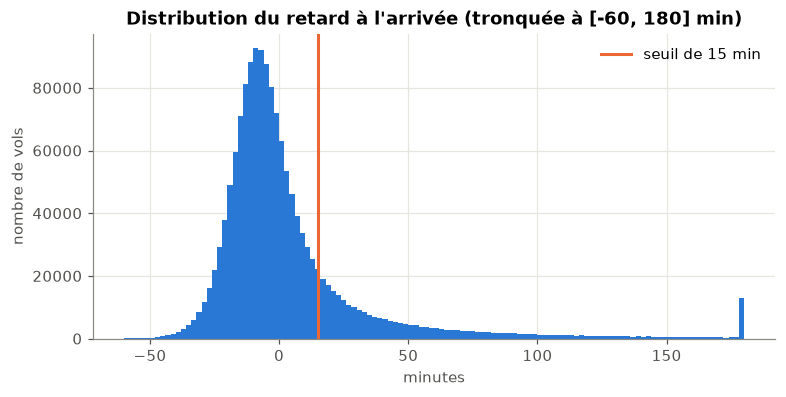

count    1500000.0
mean           4.4
std           39.1
min          -82.0
25%          -13.0
50%           -5.0
75%            8.0
max         1636.0


In [5]:
df = F.ajouter_variables_calendrier(df)
MOYENNE = df["RETARD"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df["ARRIVAL_DELAY"].clip(-60, 180), bins=120, color=E.BLEU)
ax.axvline(F.SEUIL_RETARD, color=E.ORANGE, lw=2, label="seuil de 15 min")
ax.set(title="Distribution du retard à l'arrivée (tronquée à [-60, 180] min)", xlabel="minutes", ylabel="nombre de vols")
ax.legend(); plt.show()
print(df["ARRIVAL_DELAY"].describe().round(1).to_string())

**Interprétation :** la plupart des vols arrivent **en avance** (médiane de -5 minutes, car les compagnies gonflent les durées prévues). Seuls **17,9 %** dépassent 15 minutes de retard, avec une longue traîne jusqu'à plus de 24 heures. Les classes sont donc **déséquilibrées**, ce qui oriente le choix des métriques (section 6).

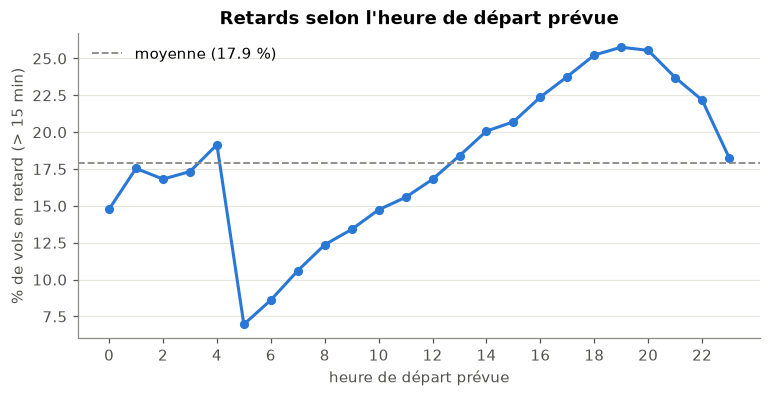

In [6]:
t = E.taux_retard(df, "HEURE_DEP")
fig, ax = plt.subplots(figsize=(8, 3.6))
E.graphique_taux(t["taux"], "Retards selon l'heure de départ prévue", "heure de départ prévue", MOYENNE, kind="line", ax=ax)
ax.set_xticks(range(0, 24, 2)); E.sauver(fig, "eda_heure"); plt.show()

**Interprétation :** c'est l'effet le plus net. Le taux de retard passe de **7 % pour les départs de 5 h** à **près de 26 % vers 19 h**. C'est l'effet « boule de neige » : un avion fait plusieurs rotations par jour, et chaque retard se répercute sur les vols suivants. Les vols de nuit (0 h à 4 h) sont rares (moins de 0,5 % des vols), donc leurs taux sont peu fiables.

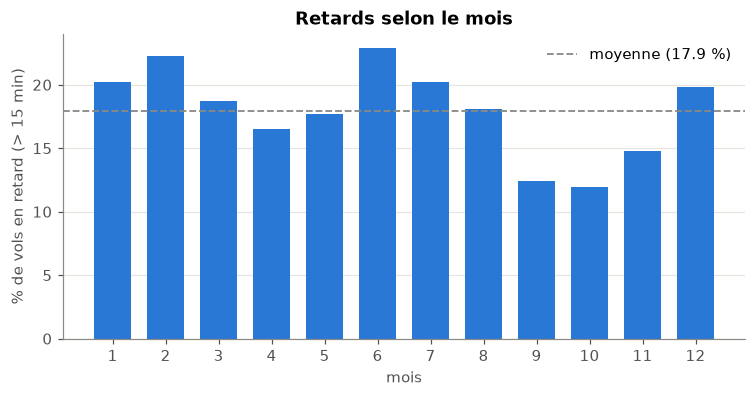

In [7]:
t = E.taux_retard(df, "MONTH")
fig, ax = plt.subplots(figsize=(8, 3.6))
E.graphique_taux(t["taux"], "Retards selon le mois", "mois", MOYENNE, ax=ax)
E.sauver(fig, "eda_mois"); plt.show()

**Interprétation :** les retards suivent la **saison**. Les pics sont en **juin** (22,9 %, orages d'été et forte affluence), en **février** (22,3 %, neige) et en décembre. **Septembre et octobre** sont les mois les plus calmes (environ 12 %). ⚠️ Conséquence pour la suite : les mois de test (septembre, novembre, décembre) ont en moyenne **moins de retards** que les mois d'entraînement. Il faudra s'en souvenir en lisant les scores, car la PR-AUC dépend de la proportion de retards.

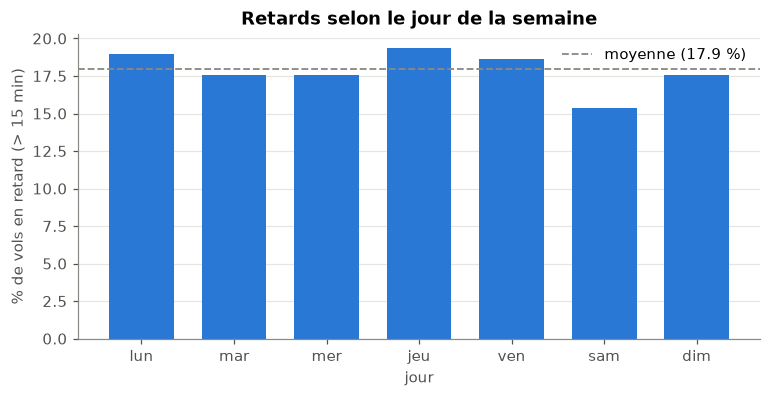

In [8]:
t = E.taux_retard(df, "DAY_OF_WEEK")
t.index = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
fig, ax = plt.subplots(figsize=(8, 3.6))
E.graphique_taux(t["taux"], "Retards selon le jour de la semaine", "jour", MOYENNE, ax=ax)
plt.show()

**Interprétation :** l'effet du jour de la semaine est **modéré**. Le **samedi** est nettement le plus calme (15,4 %, moins de vols d'affaires), alors que le **jeudi** et le **lundi** sont les plus chargés (environ 19 %).

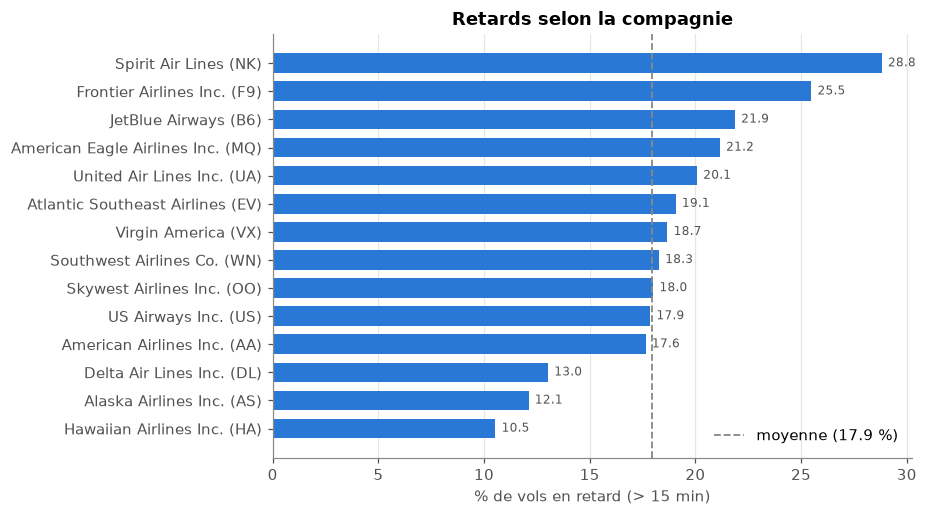

In [9]:
t = E.taux_retard(df, "AIRLINE")["taux"].sort_values()
t.index = [f"{airlines.get(c, c)} ({c})" for c in t.index]
fig, ax = plt.subplots(figsize=(7.5, 5))
E.graphique_taux(t, "Retards selon la compagnie", "", MOYENNE, kind="barh", ax=ax)
E.sauver(fig, "eda_compagnie"); plt.show()

**Interprétation :** l'écart entre compagnies va presque **du simple au triple**. Les compagnies à bas coût **Spirit (28,8 %)** et **Frontier (25,5 %)** sont les moins ponctuelles. Elles exploitent leurs avions de façon très intensive, donc avec peu de marge pour absorber un retard. **Hawaiian (10,5 %)**, **Alaska (12,1 %)** et **Delta (13,0 %)** sont les plus ponctuelles. La compagnie sera donc une variable importante.

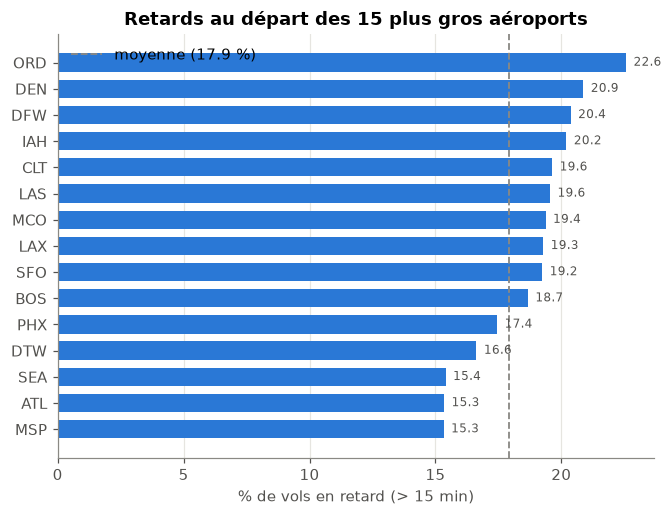

In [10]:
top = df["ORIGIN_AIRPORT"].value_counts().head(15).index
t = E.taux_retard(df[df["ORIGIN_AIRPORT"].isin(top)], "ORIGIN_AIRPORT")["taux"].sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
E.graphique_taux(t, "Retards au départ des 15 plus gros aéroports", "", MOYENNE, kind="barh", ax=ax)
plt.show()

**Interprétation :** **Chicago O'Hare (ORD, 22,6 %)** et **Denver (DEN, 20,9 %)** sont les plus touchés (hiver rigoureux, orages). **Atlanta (ATL)**, pourtant l'aéroport le plus fréquenté du monde, fait partie des meilleurs (15,3 %), avec Minneapolis (MSP) et Seattle (SEA). Le volume seul n'explique donc pas les retards : l'organisation de l'aéroport et le climat comptent aussi.